**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_009_공식형_분류_건물에너지수요예측

### **건물 에너지 수요 예측 — <span style="color:darkgreen">피크 수요 여부</span> 예측 모델 개발**
---

- 도메인 : 건물 에너지 수요 예측
- 목  표 : 피크 시간대 전력 수요 발생 여부를 예측하는 인공지능모델 개발
- 에너지관리팀은 기상·운영 데이터로 시간대별 수요를 예측해 절감 방안을 찾으려 한다.
- 피크 요금 부담이 커져 푸른솔루션의 고객 건물은 전력 수요를 미리 예측할 필요가 있다.
- 분석에는 약 920건 규모의 건물 데이터가 제공된다.
- 푸른솔루션은 피크 수요 여부를 정확히 예측할 수 있다면 의사결정의 속도와 정확도를 함께 높일 수 있을 것으로 기대하고 있다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 푸른솔루션의 데이터로 피크 시간대 전력 수요 발생 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_json, head, min, max, idxmax, quantile, copy, clip, drop, dropna, sum, isnull, reset_index, duplicated, drop_duplicates, get_dummies, info, sort_values, mean, Series, columns, shape) · NumPy(import numpy as np, abs) · seaborn(barplot) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, RobustScaler, fit_transform, transform, LogisticRegression, fit, RandomForestClassifier, coef_, predict, precision_score, LabelEncoder) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile, fit, Dense, BatchNormalization, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.84 / 5)
- 예상 소요 시간 : 약 123분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 건물 에너지 수요 예측 (에너지)

**[ 데이터 컬럼 설명 (데이터 파일명: data.json) ]**

- peakFlag              : 피크 수요 여부 (Normal, Peak)
- caseId                : 사례 식별번호
- outdoorTemp           : 외기 온도(℃)
- humidity              : 상대 습도(%)
- floorArea             : 연면적(천㎡)
- occupancy             : 재실 인원 비율(%)
- windSpeed             : 풍속(m/s)
- solarRad              : 일사량(MJ/㎡)
- itLoadKw              : 전산 설비 부하(kW)
- lagLoadKw             : 전일 동시각 전력(kW)
- contract              : 계약 종별
- region                : 지역
- dayType               : 요일 구분

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 수치 계산을 위해 NumPy 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: NumPy(import numpy as np) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `numpy`
- 별칭(alias) : `np`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import numpy as np



In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답01 = 'numpy'


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 5글자이고 첫 글자는 `n` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import num__ as np

정답01 = 'num__'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 제시된 가이드에 맞춰 파일을 읽어 df_raw 에 저장하고 처음 5개 행을 확인하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_json, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 아래 안내대로 코드를 작성하고 실행하세요
    - 읽은 결과를 담을 변수 : df_raw / 읽어 올 파일 : data.json
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 파일 형식은 JSON(records) 입니다
- **[결과 변수]** 결과는 반드시 `df_raw` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_raw.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 5점

---

In [4]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

import pandas as pd

df_raw = pd.read_json('aa22-m4-data.json')
df_raw.head(5)

print(df_raw.shape)

(917, 13)


In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(917, 13)

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_json`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_raw` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

df_raw = pd.read_json('./data.json')
df_raw.head(5)

# [df_raw] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_raw.shape)
```

</details>

### **3. 외기 온도(℃)(outdoorTemp)의 값이 어느 범위에 걸쳐 있는지, 가장 큰 값이 어느 행에 있는지 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(min, max, idxmax) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 의 outdoorTemp 컬럼에서 최솟값을 `col_min`, 최댓값을 `col_max`, **최댓값이 있는 행의 인덱스**를 `max_idx` 에 담으세요
    - 최솟값은 `min()`, 최댓값은 `max()`, 최댓값의 인덱스는 `idxmax()` 를 사용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 코드 셀 맨 아래에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [6]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

col_min = df_raw['outdoorTemp'].min()
col_max = df_raw['outdoorTemp'].max()
max_idx = df_raw['outdoorTemp'].idxmax()


In [5]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답03 = 'idxmax'


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

최솟값·최댓값을 구하는 메서드와, 최댓값의 위치(인덱스)를 구하는 메서드를 각각 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `min`, `max`, `idxmax`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
col_min = df_raw['outdoorTemp'].min()
col_max = df_raw['outdoorTemp'].max()
max_idx = df_raw['outdoorTemp'].idx___()

정답03 = 'idx___'   # 빈칸에 넣은 단어
```

</details>

### **4. 계약 종별(contract) 별 외기 온도(℃)(outdoorTemp)의 평균 수준을 비교하고자 합니다. barplot 으로 시각화하십시오.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(barplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- seaborn 의 barplot 으로 그래프를 그리세요
- X축: contract, Y축: outdoorTemp
- 오차 막대는 표시하지 않습니다(errorbar=None)
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50857 (\N{HANGUL SYLLABLE YONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50977 (\N{HANGUL SYLLABLE YUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

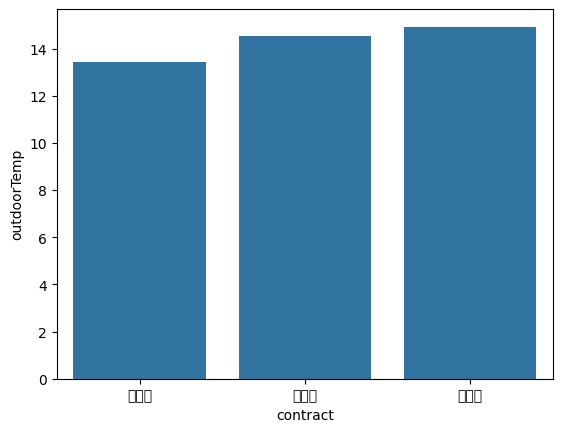

In [7]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.barplot(data=df_raw, x='contract', y='outdoorTemp', errorbar=None)
plt.show()


In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답04 = 'barplot'


<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

범주별 평균을 막대로 비교하는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.barplot`. 정답은 7글자이고 첫 글자는 `b` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.barp___(data=df_raw, x='contract', y='outdoorTemp', errorbar=None)
plt.show()

정답04 = 'barp___'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 전산 설비 부하(kW)(itLoadKw) 컬럼의 이상치는 삭제하지 않고 정상 범위의 경계값으로 대체하고자 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, clip, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_raw
    - IQR 기준(K=2.0)으로 lower_fence, upper_fence 를 산출하세요
    - itLoadKw 값이 두 fence 를 벗어나면 가장 가까운 fence 값으로 바꾸세요(행은 삭제하지 않음)
    - 식별자 컬럼 caseId 를 삭제한 사본에 적용해 df_clean 에 보관하세요
- **[결과 변수]** 결과는 반드시 `df_clean` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_clean.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [8]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

q1 = df_raw['itLoadKw'].quantile(0.25)
q3 = df_raw['itLoadKw'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

df_clean = df_raw.drop(columns=['caseId']).copy()
df_clean['itLoadKw'] = df_clean['itLoadKw'].clip(lower=lower_fence, upper=upper_fence)

print(df_clean.shape)

(917, 12)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(917, 12)

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

값을 삭제하는 대신 범위 안으로 잘라 넣는 메서드를 쓰세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `clip`, `quantile`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_clean` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
q1 = df_raw['itLoadKw'].quantile(0.25)
q3 = df_raw['itLoadKw'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

df_clean = df_raw.drop(columns=['caseId']).copy()
df_clean['itLoadKw'] = df_clean['itLoadKw'].clip(lower=lower_fence, upper=upper_fence)

# [df_clean] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_clean.shape)
```

</details>

### **6. 결측치가 있는 컬럼을 지정해 해당 행만 삭제하려 합니다.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_clean
    - 결측치가 있는 컬럼(floorArea)에 결측이 있는 행을 삭제하세요 (dropna 의 subset 옵션)
    - 결과는 df_filled 에 보관하세요
- **[결과 변수]** 결과는 반드시 `df_filled` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_filled.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [9]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_filled = df_clean.dropna(subset=['floorArea'])

print(df_filled.shape)

(842, 12)


In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(842, 12)

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측 행 삭제 메서드에 대상 컬럼 목록을 지정하는 옵션이 있습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `dropna`, `subset`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_filled` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
df_filled = df_clean.dropna(subset=['floorArea'])
print(df_filled.isnull().sum().sum())

# [df_filled] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_filled.shape)
```

</details>

### **7. 데이터에 완전히 동일한 행이 중복되어 있으면 모델이 편향될 수 있습니다. 중복 데이터를 처리하십시오.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(sum, reset_index, duplicated, drop_duplicates) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `df_filled`
- 대상 데이터프레임 : df_filled
- `duplicated()` 로 중복 행의 개수를 구해 변수 `dup_count` 에 저장하고, `drop_duplicates()` 로 중복 행을 제거한 뒤 인덱스를 0부터 다시 매겨 df_filled 에 담으세요
- **[정답07]** 제거된 중복 행(`dup_count`)은 몇 개입니까?
- 남은 문자열 컬럼 contract, region, dayType 을(를) get_dummies(drop_first=True)로 인코딩해 df_final 에 저장하세요
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [10]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['contract', 'region', 'dayType'], drop_first=True)
df_final.info()

df_final.duplicated().sum()


중복 행 개수: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   peakFlag      835 non-null    object 
 1   outdoorTemp   835 non-null    float64
 2   humidity      835 non-null    int64  
 3   floorArea     835 non-null    float64
 4   occupancy     835 non-null    float64
 5   windSpeed     835 non-null    float64
 6   solarRad      835 non-null    float64
 7   itLoadKw      835 non-null    float64
 8   lagLoadKw     835 non-null    float64
 9   contract_산업용  835 non-null    bool   
 10  contract_일반용  835 non-null    bool   
 11  region_서울     835 non-null    bool   
 12  region_영남     835 non-null    bool   
 13  region_충청     835 non-null    bool   
 14  region_호남     835 non-null    bool   
 15  dayType_주말    835 non-null    bool   
 16  dayType_평일    835 non-null    bool   
dtypes: bool(8), float64(7), int64(1), object(1)
memory usage: 65.4

np.int64(0)

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답07 = '7'


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

중복 여부를 불리언으로 구해 합계를 센 뒤, 중복을 제거합니다. 남은 문자열 컬럼을 모두 0/1 컬럼으로 바꿉니다. duplicated() 결과의 합계입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `duplicated`, `drop_duplicates`, `reset_index`, `pd.get_dummies`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['contract', 'region', 'dayType'], drop_first=True)
df_final.info()

# [정답07] 실행한 결과를 입력하세요
df_filled.duplicated().sum()
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인하려 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_final
    - 피크 수요 여부(peakFlag) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
    - 훈련과 검증 데이터셋의 클래스 비율을 동일하게 하는 옵션(stratify)을 설정하세요
    - 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
    - 데이터를 훈련 70 : 검증 30 로 분할합니다 (train_size=0.7)
    - 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
    - 난수 시드(random_state)는 100 로 설정하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [12]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = df_final.drop('peakFlag', axis=1)
y = df_final['peakFlag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.7, random_state=100, stratify=y)

print(len(X_valid))

251


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
251

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('peakFlag', axis=1)
y = df_final['peakFlag']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.7, random_state=100, stratify=y)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (중앙값/IQR 기반(이상치에 강건))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(RobustScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 RobustScaler 를 import 하세요
    - RobustScaler 를 scaler 변수에 설정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** RobustScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수점 아래 둘째 자리까지 작성하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [15]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-2.12)

In [13]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답09 = '-2.12'


<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 피크 수요 여부(peakFlag)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LogisticRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LogisticRegression, fit, RandomForestClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LogisticRegression 모델을 아래와 같이 만들어 `lr` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : C=0.1
    - 최대 반복 횟수(max_iter) : 1000
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=50, max_depth=4
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lr`(LogisticRegression) 의 **훈련 데이터** 점수 `lr.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 기입하세요
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [17]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=0.1, max_iter=1000)
lr.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

round(lr.score(X_train, y_train), 3)


0.824

In [16]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답10 = '0.824'


<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LogisticRegression`, `fit`, `RandomForestClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=0.1, max_iter=1000)
lr.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lr.score(X_train, y_train), __)
```

</details>

### **11. LogisticRegression 모델의 회귀 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석할 계획입니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, mean, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `np` · 2번 `pd` · 8번 `X` · 10번 `lr`
- 학습된 `lr` 의 계수(coef_)의 **절댓값**을 산출하세요 (다중 클래스처럼 2차원이면 클래스 축으로 평균)
    - 변수명(X.columns)과 매핑한 Series 를 내림차순으로 정렬해 `coef_s` 에 담으세요
- **[정답11]** 계수 크기가 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [18]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

coef_s = pd.Series(np.abs(lr.coef_).mean(axis=0), index=X.columns).sort_values(ascending=False)

coef_s.index[0]


'outdoorTemp'

In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답11 = 'outdoorTemp'


<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef = np.abs(lr.coef_)
coef = coef.mean(axis=0) if coef.ndim > 1 else coef
coef_s = pd.Series(coef, index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LogisticRegression와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, precision_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `lr`, `rf`
- 아래 가이드에 따라 각 모델의 Precision(macro) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 lr 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Precision(macro) 값을 각각 lr_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Precision(macro) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LogisticRegression / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [20]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import precision_score

y_pred_lr = lr.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

lr_score = precision_score(y_valid, y_pred_lr, average='macro')
rf_score = precision_score(y_valid, y_pred_rf, average='macro')
print(lr_score, rf_score)


0.821290944123314 0.7655841157457288


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답12 = 'LogisticRegression'


<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. Precision(macro) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import precision_score

y_pred_lr = lr.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

lr_score = precision_score(y_valid, y_pred_lr, average='macro')
rf_score = precision_score(y_valid, y_pred_rf, average='macro')
print(lr_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(lr_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)

### **13. 피크 수요 여부(peakFlag)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · scikit-learn(LabelEncoder, fit_transform, transform) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - 딥러닝 프레임워크는 tensorflow 를 씁니다
    - Sequential 이 아니라 **함수형 API**로 구성하세요: `Input(shape=(X_train.shape[1],))` 로 입력을 만들고, 각 층을 `층(앞 텐서)` 형태로 이어 붙인 뒤 `Model(inputs=..., outputs=...)` 로 `model` 을 만드세요
    - 은닉층은 Dense 레이어 2개(노드 수 [16, 8]), 활성화 함수는 'tanh' 로 하세요
    - 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
    - 이번 모델에는 Dropout 을 넣지 않습니다
    - EarlyStopping 으로 20번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 담으세요
    - 출력층은 노드 1개, activation='sigmoid' 로 하세요
    - compile 설정 : optimizer='rmsprop', loss='binary_crossentropy', metrics=[accuracy]
    - batch_size 는 32, epochs 는 20 로 학습하고 학습정보는 history 변수에 보관하세요 (검증은 훈련 데이터의 20% 를 쓰는 validation_split=0.2 로 지정)
    - 안내하지 않은 파라미터는 지정하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**


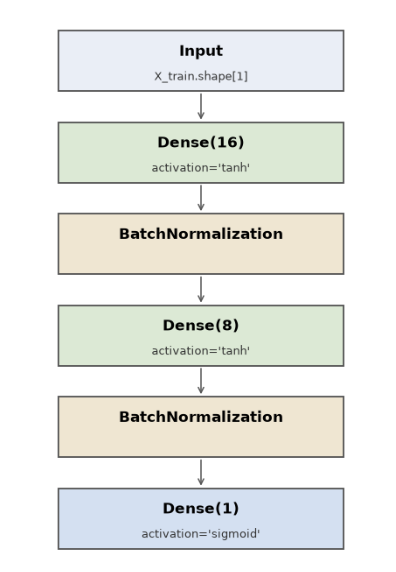


In [24]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(16, activation='tanh')(inputs)
x = BatchNormalization()(x)
x = Dense(8, activation='tanh')(x)
x = BatchNormalization()(x)
outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=20, batch_size=32,
                    validation_split=0.2,
                    callbacks=cb_list)

print(model.count_params())

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - accuracy: 0.4368 - loss: 0.8932 - val_accuracy: 0.5556 - val_loss: 0.6829
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5375 - loss: 0.7605 - val_accuracy: 0.6581 - val_loss: 0.6408
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.6017 - loss: 0.6822 - val_accuracy: 0.6838 - val_loss: 0.6032
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6638 - loss: 0.6243 - val_accuracy: 0.7265 - val_loss: 0.5692
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7045 - loss: 0.5806 - val_accuracy: 0.7692 - val_loss: 0.5388
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.7302 - loss: 0.5481 - val_accuracy: 0.7863 - val_loss: 0.5123
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.7473 - loss: 0.5246 - val_accuracy: 0.7778 - val_loss: 0.4897
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.7645 - loss: 0.5072 - val_accuracy: 0.7863 - 

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
513

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

입력 텐서를 만들고, 층을 하나씩 앞 텐서에 적용해 이어 붙이세요. 마지막에 Model 로 묶습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Input`, `Dense`, `Dropout`, `Model`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(16, activation='tanh')(inputs)
x = BatchNormalization()(x)
x = Dense(8, activation='tanh')(x)
x = BatchNormalization()(x)
outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=20, batch_size=32,
                    validation_split=0.2,
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 Loss 과 검증 Loss 2가지를 모두 표시하세요
- legend 에는 'train', 'val' 를 쓰세요
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

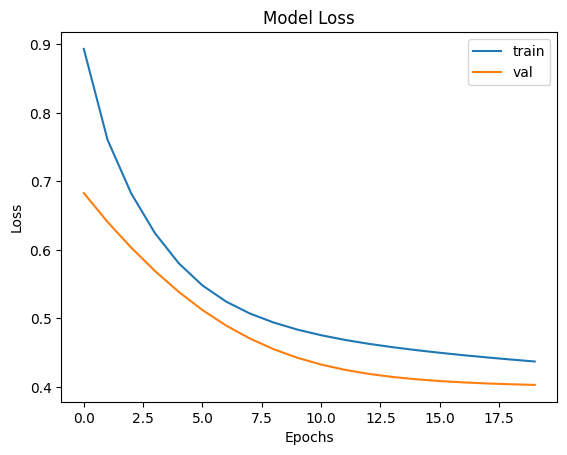

In [25]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답14_1 = 'plot'
정답14_2 = 'history'


<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. fit 이 돌려준 학습 기록 객체의 변수명입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 7글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.pl__(hist___.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

정답14_1 = 'pl__'   # 빈칸 1에 넣은 단어
정답14_2 = 'hist___'   # 빈칸 2에 넣은 단어
```

</details>